# 09 · Genetik algoritma ile parametre arama

**Amaç:** Sonlu fark gradyanına alternatif olarak seçim, çaprazlama ve mutasyonla devre parametrelerini aramak.

**Okuma notu:** Kodda fitness eğitim doğruluğudur; eski docstring içindeki test accuracy ifadesi hatalıdır. Test doğruluğu nesiller boyunca izlenir. Donanım değerlendirmesi 33 örnektir.

**Durum:** Staj çalışması arşivi. Aşağıdaki çıktılar ZIP içinde kayıtlı geçmiş çalıştırmalara aittir; bu yayına hazırlık sırasında üretilmiş yeni deney sonuçları değildir. Deney kodu ve eski açıklamalar gelişim sürecini göstermek için korunmuştur; yöntem düzeltmeleri ve sınırlılıklar için [çalışma rehberini](../../docs/CALISMA_REHBERI.md), [sonuçları](../../docs/SONUCLAR.md) ve [yöntem incelemesini](../../docs/YONTEM_VE_SINIRLAR.md) okuyun.

**English:** Historical internship experiment. See the [English overview](../../README_EN.md). Saved outputs are historical evidence, not a fresh reproducibility claim.

**Güvenlik düzeltmesi:** Hesap kayıtlarını bütünüyle yazdıran hücre yalnız hesap adlarını gösterecek şekilde değiştirildi; eski hesap çıktısı kaldırıldı. Bu hücre yeniden çalıştırılmadı.



## Hedef: Basit bir QNN ile iris veri kümesi üzerinde 2'li sınıflandırma yaparak IBM Quantum Bilgisayarı üzerinde çalıştırdığım kodu fine-tune etmek.

Eğitim ve yoğun denemeleri AerSimulator ile, inference/ölçüm kısmını IBM cihazında yapacağız.

Bu adımda tek tek job atmak yerine batch çalıştıracağız (zaman tasarrufu).

In [ ]:
import sklearn, qiskit, qiskit_aer, qiskit_ibm_runtime, numpy as np, matplotlib

print("scikit-learn:", sklearn.__version__)
print("Qiskit:", qiskit.__version__)
print("Aer:", qiskit_aer.__version__)
print("Runtime:", qiskit_ibm_runtime.__version__)
print("NumPy:", np.__version__)
print("Matplotlib:", matplotlib.__version__)



scikit-learn: 1.7.1
Qiskit: 1.2.4
Aer: 0.16.0
Runtime: 0.29.0
NumPy: 2.3.3
Matplotlib: 3.10.5


In [ ]:
from qiskit_ibm_runtime import QiskitRuntimeService

# Güvenlik düzeltmesi: yalnız hesap adlarını göster; kayıtları/token değerlerini yazdırma.
print("Kayıtlı hesap adları:", list(QiskitRuntimeService.saved_accounts()))


In [ ]:
from qiskit_ibm_runtime import QiskitRuntimeService

service = QiskitRuntimeService()   # kayıtlı hesabı otomatik okur
print("✅ Service OK")

# Örnek: erişebildiğin backend'leri listele
backends = service.backends()
print("Toplam backend:", len(backends))
print("İlk 5 backend:", [b.name for b in backends[:5]])


✅ Service OK
Toplam backend: 2
İlk 5 backend: ['ibm_brisbane', 'ibm_torino']


In [ ]:
from qiskit_ibm_runtime import QiskitRuntimeService

N = 4
INSTANCE = "YOUR_INSTANCE_CRN"
service = QiskitRuntimeService(channel="ibm_cloud", instance=INSTANCE)

# Gerçek cihaz adayları (operational ve en az 4 qubit)
candidates = service.backends(simulator=False, operational=True)
def num_qubits(b):
    return getattr(b, "num_qubits", getattr(getattr(b, "configuration", lambda: None)(), "n_qubits", 0))
candidates = [b for b in candidates if num_qubits(b) >= N]
print("Erişilebilir cihazlar:", [(b.name, num_qubits(b)) for b in candidates])

# Kuyruğu en kısa olanı seç
def queue_len(b):
    try:
        st = b.status()
        return getattr(st, "pending_jobs", getattr(st, "queue_size", 10**9))
    except Exception:
        return 10**9

backend = None
if candidates:
    candidates.sort(key=queue_len)
    backend = candidates[0]

if backend is None:
    backend = service.backend("ibmq_qasm_simulator")
    print("Uygun gerçek cihaz yok → simülatör seçildi.")

print(f"Seçilen backend: {backend.name} | Qubit sayısı: {num_qubits(backend)}")


Erişilebilir cihazlar: [('ibm_brisbane', 127), ('ibm_torino', 133)]
Seçilen backend: ibm_torino | Qubit sayısı: 133


Güzel, cihazlara erişimimiz var ve bağlanabiliriz.

In [ ]:
# Servise bağlanıp eriştiğimız cihazı 'backend' nesnesi olarak alıyoruz
INSTANCE = "YOUR_INSTANCE_CRN"

service = QiskitRuntimeService(channel="ibm_cloud", instance=INSTANCE)

backend = service.backend("ibm_torino")
print("Backend:", backend.name)


Backend: ibm_torino


In [ ]:
# Devre kurmak ve parametrizasyon için temel importlar
import numpy as np, time
from sklearn import datasets, model_selection
from sklearn.preprocessing import MinMaxScaler
import matplotlib.pyplot as plt

from qiskit.circuit import QuantumCircuit, QuantumRegister, ClassicalRegister, ParameterVector
from qiskit import transpile
from qiskit_ibm_runtime import QiskitRuntimeService, Sampler, Options
from qiskit_aer import AerSimulator



N = 4  # 4 qubit kullanacağız

In [ ]:
# Veri hazırlığı ve ölçekleme (0, π) — pratik hazırlık

# 1) Iris (binary: ilk 100 kayıt = Setosa(0), Versicolor(1))
iris = datasets.load_iris()
X = iris.data[:100]
Y = iris.target[:100]

# 2) Train/Test böl
X_train, X_test, Y_train, Y_test = model_selection.train_test_split(
    X, Y, test_size=0.33, random_state=42, stratify=Y
)

# 3) Feature scaling: [0, π]  → RX açıları için uygun
scaler = MinMaxScaler(feature_range=(0, np.pi))
X_train_s = scaler.fit_transform(X_train)
X_test_s  = scaler.transform(X_test)

# 4) Hızlı kontroller (N = 4 ile uyum?)
assert X_train_s.shape[1] == 4, "N=4 bekleniyordu."
assert np.all((X_train_s >= 0) & (X_train_s <= np.pi + 1e-9)), "Özellikler [0, π] aralığında olmalı."

print("X_train_s şekli:", X_train_s.shape, "| Örnek aralık:", (X_train_s.min(), X_train_s.max()))

np.random.seed(42)

X_train_s şekli: (67, 4) | Örnek aralık: (np.float64(0.0), np.float64(3.141592653589794))


In [ ]:

def feature_map(X_or_phi):
    q = QuantumRegister(N, "q")
    c = ClassicalRegister(1, "c")   # sadece q0'ı ölçeceğiz
    qc = QuantumCircuit(q, c, name="feature_map")
    for i, x in enumerate(X_or_phi):
        qc.rx(x, i)
    return qc, c

def variational_circuit(qc, theta):
    for i in range(N-1):
        qc.cx(i, i+1)
    qc.cx(N-1, 0)
    for i in range(N):
        qc.ry(theta[i], i)
    return qc


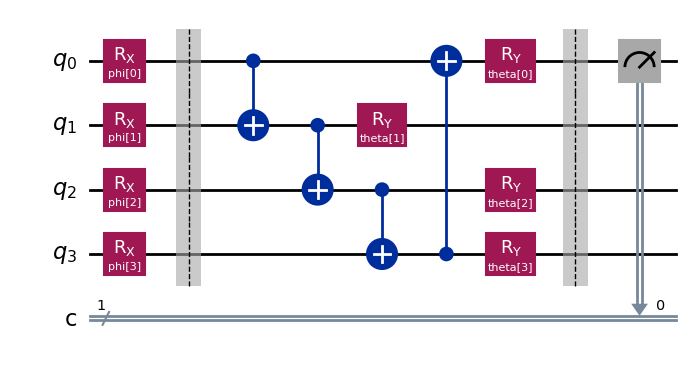

In [ ]:
#Parametrik şablon (phi/theta) + ölçüm
#Veriyi/parametreyi sonradan bağlayacağız.

phi   = ParameterVector('phi', N)     # veri parametreleri
theta = ParameterVector('theta', N)   # öğrenilebilir parametreler

qc, c = feature_map(phi)              #  feature_map()
qc.barrier()
qc = variational_circuit(qc, theta)   #  variational_circuit()
qc.barrier()
qc.measure(0, c[0])
                  # sadece q0'ı ölç → p(1)
qc.draw("mpl")  # Devreyi görselleştir

In [ ]:
#Hedefe göre transpile: HW ve SIM için ayrı ayrı yaparız

# QPU kapı seti ≠ AER kapı seti;
# Bu yüzdden iki şablon hazırlıyoruz.

# HW için
tqc_hw = transpile(
    qc, backend=backend,
    optimization_level=3,
    layout_method="sabre",
    routing_method="sabre",
    seed_transpiler=42
)


# SIM için
backend_sim = AerSimulator()
tqc_sim = transpile(qc, backend=backend_sim, optimization_level=1)

print("HW depth:", tqc_hw.depth(), "| SIM depth:", tqc_sim.depth())


HW depth: 33 | SIM depth: 7


In [ ]:
def quantum_nn_sim(x_vals, theta_vals, shots=2048):
    bind = {phi[i]: float(x_vals[i]) for i in range(N)}
    bind |= {theta[j]: float(theta_vals[j]) for j in range(N)}
    circ = tqc_sim.assign_parameters(bind, inplace=False)
    job = backend_sim.run(circ, shots=shots, seed_simulator=42)
    counts = job.result().get_counts()
    total = sum(counts.values()) or 1
    return counts.get('1', 0)/total

#Sim’de çalışan quantum_nn_sim (hızlı deneme/eğitim)
# Eğitim ve hızlı test için AER kullanıyoruz

Simulasyonda eğitim parametrelerinde değişiklik yaptım
shots 1024 -> 2048
delta 1e-2 -> 5e-3
Daha küçük delta + daha çok shot ile daha stabil gradyan elde etmek istiyorum.

In [ ]:

# Loss MSE
def loss(pred, target):
    return (pred - target)**2

# Gradient (Finite Difference)
def gradient_fd_sim(x, y, theta_vals, delta=5e-3, shots=2048):
    g = np.zeros_like(theta_vals, float)
    for i in range(len(theta_vals)):
        thp = theta_vals.copy(); thp[i]+=delta
        thm = theta_vals.copy(); thm[i]-=delta
        p_plus  = quantum_nn_sim(x, thp, shots=shots)
        p_minus = quantum_nn_sim(x, thm, shots=shots)
        g[i] = ((p_plus - y)**2 - (p_minus - y)**2)/(2*delta)
    return g


# Accuracy
def accuracy_sim(X, Y, theta_vals, shots=2048, threshold=0.5):
    correct=0
    for x,y in zip(X,Y):
        p1 = quantum_nn_sim(x, theta_vals, shots=shots)
        correct += int((p1>=threshold) == int(y))
    return correct/len(Y)


In [ ]:
# (EĞİTİM) GENETİK ALGORİTMA GA TABANLI QNN EĞİTİMİ


def train_ga_qnn(X_train_s, Y_train, X_test_s, Y_test,
                 generations=30, pop_size=20,
                 elite_frac=0.2, mutation_rate=0.2, mutation_scale=0.1,
                 shots=1024, seed=42):
    """
    Basit GA (Genetik Algoritma) ile QNN eğitimi.
    - Popülasyon: theta vektörleri
    - Fitness: test accuracy
    """
    rng = np.random.default_rng(seed)

    # Başlangıç popülasyonu (rastgele theta'lar [0, π])
    population = [rng.random(N) * np.pi for _ in range(pop_size)]

    history = {"best_acc": [], "test_acc": [], "train_acc": []}

    for gen in range(generations):
        # --- Fitness hesapla ---
        fitness = []
        for theta in population:
            acc = accuracy_sim(X_train_s, Y_train, theta, shots=shots, threshold=0.5)
            fitness.append(acc)

        # En iyi bireyi kaydet
        best_idx = int(np.argmax(fitness))
        best_theta = population[best_idx]
        best_train_acc = fitness[best_idx]
        best_test_acc = accuracy_sim(X_test_s, Y_test, best_theta, shots=shots, threshold=0.5)

        history["best_acc"].append(fitness[best_idx])
        history["train_acc"].append(best_train_acc)
        history["test_acc"].append(best_test_acc)

        print(f"Gen {gen:02d} | Best TrainAcc={best_train_acc:.3f} | TestAcc={best_test_acc:.3f}")

        # --- Selection (elitizm + turnuva) ---
        elite_count = max(1, int(elite_frac * pop_size))
        elite_indices = np.argsort(fitness)[-elite_count:]
        new_population = [population[i] for i in elite_indices]

        while len(new_population) < pop_size:
            # İki ebeveyn seç
            parents = rng.choice(population, size=2, replace=False)
            p1, p2 = parents
            # Crossover (tek-nokta)
            cross_pt = rng.integers(1, N)
            child = np.concatenate([p1[:cross_pt], p2[cross_pt:]])
            # Mutation
            if rng.random() < mutation_rate:
                mut = rng.normal(0, mutation_scale, size=N)
                child = np.clip(child + mut, 0, np.pi)
            new_population.append(child)

        population = new_population

    return best_theta, history


In [ ]:
# Eğitim (simde) → θ bul
# θ’yı simde öğren, QPU’da inference yap.

quantum_nn = lambda x,t: quantum_nn_sim(x, t, shots=500)

optimal_theta, history = train_ga_qnn(
    X_train_s, Y_train, X_test_s, Y_test,
    generations=30,     # GA nesil sayısı (epochs yerine)
    pop_size=20,        # popülasyon büyüklüğü
    elite_frac=0.2,     # elitizm oranı
    mutation_rate=0.3,  # mutasyon ihtimali
    mutation_scale=0.1, # mutasyon boyutu
    shots=1024
)

print("SIM acc (train/test):",
      history["train_acc"][-1], history["test_acc"][-1])


Gen 00 | Best TrainAcc=0.851 | TestAcc=0.818
Gen 01 | Best TrainAcc=0.851 | TestAcc=0.818
Gen 02 | Best TrainAcc=0.851 | TestAcc=0.818
Gen 03 | Best TrainAcc=0.851 | TestAcc=0.818
Gen 04 | Best TrainAcc=0.851 | TestAcc=0.818
Gen 05 | Best TrainAcc=0.851 | TestAcc=0.818
Gen 06 | Best TrainAcc=0.851 | TestAcc=0.818
Gen 07 | Best TrainAcc=0.851 | TestAcc=0.818
Gen 08 | Best TrainAcc=0.851 | TestAcc=0.818
Gen 09 | Best TrainAcc=0.851 | TestAcc=0.758
Gen 10 | Best TrainAcc=0.851 | TestAcc=0.818
Gen 11 | Best TrainAcc=0.851 | TestAcc=0.788
Gen 12 | Best TrainAcc=0.851 | TestAcc=0.818
Gen 13 | Best TrainAcc=0.851 | TestAcc=0.818
Gen 14 | Best TrainAcc=0.851 | TestAcc=0.818
Gen 15 | Best TrainAcc=0.851 | TestAcc=0.758
Gen 16 | Best TrainAcc=0.851 | TestAcc=0.758
Gen 17 | Best TrainAcc=0.851 | TestAcc=0.818
Gen 18 | Best TrainAcc=0.851 | TestAcc=0.758
Gen 19 | Best TrainAcc=0.851 | TestAcc=0.818
Gen 20 | Best TrainAcc=0.851 | TestAcc=0.818
Gen 21 | Best TrainAcc=0.851 | TestAcc=0.758
Gen 22 | B

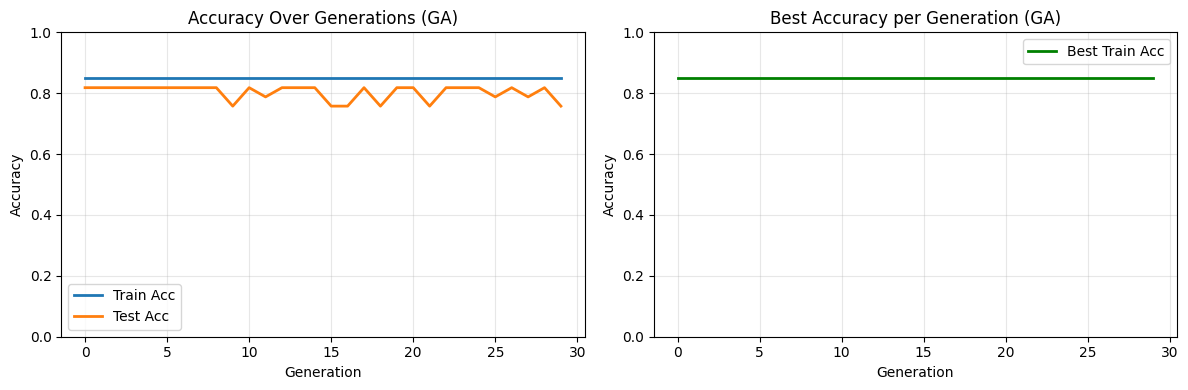

(<Figure size 1200x400 with 2 Axes>,
 (<Axes: title={'center': 'Accuracy Over Generations (GA)'}, xlabel='Generation', ylabel='Accuracy'>,
  <Axes: title={'center': 'Best Accuracy per Generation (GA)'}, xlabel='Generation', ylabel='Accuracy'>))

In [ ]:
def plot_training_ga(history, savepath=None):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

    # Accuracy
    ax1.plot(history["train_acc"], linewidth=2, label="Train Acc")
    ax1.plot(history["test_acc"],  linewidth=2, label="Test Acc")
    ax1.set_xlabel('Generation'); ax1.set_ylabel('Accuracy')
    ax1.set_title('Accuracy Over Generations (GA)')
    ax1.grid(True, alpha=0.3); ax1.legend(); ax1.set_ylim(0, 1)

    # Best accuracy (elit çözümün evrimi)
    ax2.plot(history["best_acc"], linewidth=2, label="Best Train Acc", color="green")
    ax2.set_xlabel('Generation'); ax2.set_ylabel('Accuracy')
    ax2.set_title('Best Accuracy per Generation (GA)')
    ax2.grid(True, alpha=0.3); ax2.legend(); ax2.set_ylim(0, 1)

    plt.tight_layout()
    if savepath:
        plt.savefig(savepath, bbox_inches='tight', dpi=150)
    plt.show()
    return fig, (ax1, ax2)


# Çağrı
plot_training_ga(history)


#### Simülatörde eğittik

AerSimulator ile parametreleri (θ) optimize ettik.

Gradient’i finite-difference yöntemiyle hesapladık.

Eğitim sonucunda bir optimal_theta bulduk.

In [ ]:
# --- V1/V2 ile uyumlu p(1) çıkarıcı ---
def _p1_from_quasi(qd):
    # V1: QuasiDistribution
    try:
        bp = qd.binary_probabilities()
        return float(bp.get('1', bp.get(1, 0.0)))
    except Exception:
        return float(qd.get('1', qd.get(1, 0.0)))  # bazı sürümlerde dict

def _p1_from_counts(counts):
    tot = sum(counts.values()) or 1
    # Tek cbit ölçtüğümüz için anahtarlar '0'/'1' olmalı
    return float(counts.get('1', counts.get(1, 0)))/tot

def extract_p1_list_any(result):
    """
    Sampler V1 (SamplerResult.quasi_dists) ve
    Sampler V2 (PrimitiveResult -> SamplerPubResult) için sağlam p(1) listesi.
    """
    # --- V1 yolu: SamplerResult.quasi_dists ---
    if hasattr(result, "quasi_dists"):
        return [_p1_from_quasi(qd) for qd in result.quasi_dists]

    # --- V2 yolu: PrimitiveResult / SamplerPubResult listesi ---
    out = []
    try:
        for pub in result:  # result[0], result[1], ...
            # 1) En kolayı: tüm kayıtları birleştir
            counts = None
            try:
                jd = pub.join_data()                 # V2 önerilen yol
                if hasattr(jd, "get_counts"):
                    counts = jd.get_counts()
            except Exception:
                pass

            # 2) Alternatif: data.meas.* üzerinden
            if counts is None:
                data = getattr(pub, "data", None)
                meas = getattr(data, "meas", None) if data is not None else None
                if meas is not None:
                    try:
                        # bazı build’lerde direkt olasılık döner
                        bp = meas.binary_probabilities()
                        out.append(float(bp.get('1', bp.get(1, 0.0))))
                        continue
                    except Exception:
                        try:
                            counts = meas.get_counts()
                        except Exception:
                            counts = None

            if counts is not None:
                out.append(_p1_from_counts(counts))
                continue

        if out:
            return out
    except Exception:
        pass

    # Teşhis için: tip bilgisini göster
    raise RuntimeError(
        f"Result formatı desteklenmiyor. type(result)={type(result)}; "
        "Bu durumda result[0] nesnesindeki .join_data() veya .data.meas.* yollarını deneyin."
    )


In [ ]:

# --- 2) Devre bağlama  ---
def make_bound_circuits_hw(X_batch, theta_vals):
    base = tqc_hw
    circs = []
    for x in X_batch:
        bind = {phi[i]: float(x[i]) for i in range(N)}
        bind |= {theta[i]: float(theta_vals[i]) for i in range(N)}
        circs.append(base.assign_parameters(bind, inplace=False))
    return circs


Verilen bir veri batch’i (X_batch) ve öğrenilmiş parametreler (theta_vals) ile, transpile edilmiş şablon devre (tqc_hw) üzerine bu parametreleri bağlamak ve çalıştırmaya hazır devre listesi döndürmek.

In [ ]:
# --- 3) Job gönder (job_id değil, job döndür) ---

def submit_hw_job(X_batch, theta_vals, shots=1024):
    circs = make_bound_circuits_hw(X_batch, theta_vals)
    job = Sampler(backend=backend).run(circs, shots=shots)
    print("HW Job ID:", job.job_id())
    return job   # <— ÖNEMLİ: job_id değil

#Donanımda deneyi başlatır, job nesnesini geri verir.

shots sayısını burada da arttırdık 256 ->

In [ ]:
def best_threshold(p1, y_true, grid=np.linspace(0.35, 0.65, 16)):
    y_true = np.array(y_true[:len(p1)], int)
    best = (None, -1.0)
    for t in grid:
        preds = (np.array(p1) >= t).astype(int)
        acc = (preds == y_true).mean()
        if acc > best[1]:
            best = (t, acc)
    return best  # (threshold, accuracy)


In [ ]:
# --- 4) Accuracy: job veya job_id ile çalışabilen iki kısa yardımcı ---
def fetch_hw_accuracy_from_job(job, Y_slice, threshold=0.50):
    res = job.result()
    p1 = extract_p1_list_any(res)
    m = min(len(p1), len(Y_slice))
    preds = (np.array(p1[:m]) >= threshold).astype(int)
    acc = (preds == np.array(Y_slice[:m], int)).mean()
    return float(acc), p1[:m], preds.tolist()

#Job nesnesinden sonuçları alır, accuracy hesaplar.



def fetch_hw_accuracy_from_id(job_id, Y_slice, threshold=0.50):
    job = service.job(job_id)
    return fetch_hw_accuracy_from_job(job, Y_slice, threshold)

#Eski job ID’lerinden de accuracy hesaplamanı sağlar. BURAYI İNCELE

In [ ]:
theta_vals = optimal_theta
subset = len(X_test_s)   # yani test setinin tamamı
job = submit_hw_job(X_test_s[:subset], theta_vals, shots=256)


[LOCAL_TEMP_PATH] DeprecationWarning: The 'backend' keyword arguments are deprecated as of qiskit-ibm-runtime 0.24.0 and will be removed no sooner than 3 months after the release date. Please use the 'mode' parameter instead.
  job = Sampler(backend=backend).run(circs, shots=shots)


HW Job ID: [REDACTED_JOB_ID]


In [ ]:
# Donanımdan sonuçları çek ve accuracy hesapla
acc_hw, p1_hw, preds_hw = fetch_hw_accuracy_from_job(
    job, Y_test[:subset], threshold=0.50
)

print(f"HW accuracy (subset={len(p1_hw)}): {acc_hw:.3f}")
print("Backend:", backend.name)
print("p1_hw:", [round(p, 3) for p in p1_hw])
print("preds_hw:", preds_hw)
print("y_true:", list(map(int, Y_test[:len(p1_hw)])))


HW accuracy (subset=33): 0.758
Backend: ibm_torino
p1_hw: [0.52, 0.559, 0.477, 0.492, 0.434, 0.281, 0.359, 0.477, 0.441, 0.555, 0.578, 0.418, 0.535, 0.441, 0.707, 0.496, 0.562, 0.367, 0.355, 0.484, 0.559, 0.621, 0.383, 0.496, 0.465, 0.492, 0.359, 0.551, 0.504, 0.547, 0.59, 0.523, 0.477]
preds_hw: [1, 1, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 1, 0, 1, 0, 1, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 0]
y_true: [1, 0, 1, 0, 0, 0, 0, 0, 0, 1, 1, 0, 1, 1, 0, 1, 1, 0, 0, 0, 1, 1, 0, 0, 1, 1, 0, 1, 1, 0, 1, 1, 0]
